# EDA

### import the dependencies

In [209]:
import re
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [210]:
fake = pd.read_csv("../data/raw/ISOT/Fake.csv"); fake["label"] = 0
true = pd.read_csv("../data/raw/ISOT/True.csv"); true["label"] = 1

df = pd.concat([fake, true], ignore_index=True)
print(df.columns.tolist())   # title, text, subject, date, label
print(df["label"].value_counts())

['title', 'text', 'subject', 'date', 'label']
label
0    23481
1    21417
Name: count, dtype: int64


In [211]:
df.head()

,title,text,subject,date,label
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017",0
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017",0
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017",0
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017",0
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017",0


In [212]:
label_counts = df['label'].value_counts()
label_counts

label
0    23481
1    21417
Name: count, dtype: int64

### before removing nulls labels are Approximately balanced

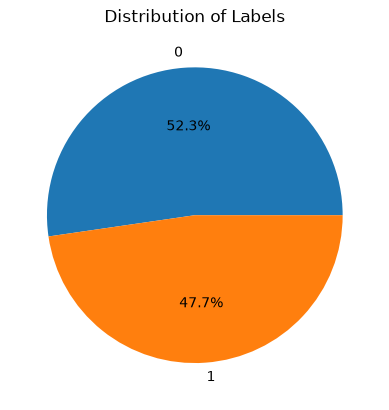

In [213]:
plt.pie(label_counts, labels=label_counts.index, autopct='%1.1f%%')
plt.title('Distribution of Labels')
plt.show()

In [214]:
df.isnull().sum()

title      0
text       0
subject    0
date       0
label      0
dtype: int64

### average of text length

In [215]:
df["n_words"] = df["text"].fillna("").str.split().str.len()

print(df["n_words"].describe())

count    44898.000000
mean       405.282284
std        351.265595
min          0.000000
25%        203.000000
50%        362.000000
75%        513.000000
max       8135.000000
Name: n_words, dtype: float64


## there are 631 empty text 630 is fake so it well cause leakage 

In [216]:
empty = df["n_words"] == 0
print(empty.sum())
print(df[empty]["label"].value_counts())

631
label
0    630
1      1
Name: count, dtype: int64


In [217]:
print(df.groupby("label")["n_words"].describe())

         count        mean         std  min    25%    50%    75%     max
label                                                                   
0      23481.0  423.197905  408.388890  0.0  240.0  363.0  506.0  8135.0
1      21417.0  385.640099  274.006204  0.0  148.0  359.0  525.0  5172.0


In [218]:
print(df.duplicated(subset="text").sum())

6252


In [219]:
conflict = df.groupby("text")["label"].nunique()
print((conflict > 1).sum())

1


In [220]:
print(df["n_words"].quantile([0.5, 0.75, 0.9, 0.95, 0.99]))

0.50     362.00
0.75     513.00
0.90     745.00
0.95     904.00
0.99    1508.12
Name: n_words, dtype: float64


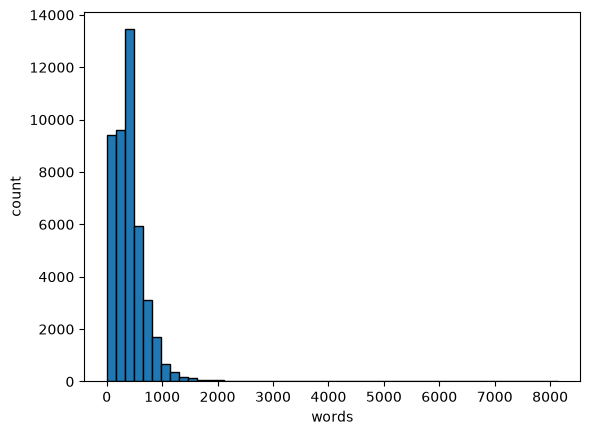

In [221]:
plt.hist(df["n_words"],bins=50,edgecolor='black')
plt.xlabel("words")
plt.ylabel("count")
plt.show()

In [222]:
print(pd.crosstab(df["subject"], df["label"]))
# we should remove subject column

label               0      1
subject                     
Government News  1570      0
Middle-east       778      0
News             9050      0
US_News           783      0
left-news        4459      0
politics         6841      0
politicsNews        0  11272
worldnews           0  10145


In [223]:
print(df.duplicated(subset="text").sum())

6252


In [224]:
df['combined_text'] = df['title'] + ' ' + df['text']
df['combined_text']

0         Donald Trump Sends Out Embarrassing New Year’...
1         Drunk Bragging Trump Staffer Started Russian ...
2         Sheriff David Clarke Becomes An Internet Joke...
3         Trump Is So Obsessed He Even Has Obama’s Name...
4         Pope Francis Just Called Out Donald Trump Dur...
                               ...                        
44893    'Fully committed' NATO backs new U.S. approach...
44894    LexisNexis withdrew two products from Chinese ...
44895    Minsk cultural hub becomes haven from authorit...
44896    Vatican upbeat on possibility of Pope Francis ...
44897    Indonesia to buy $1.14 billion worth of Russia...
Name: combined_text, Length: 44898, dtype: str

In [225]:
def clean_text(text):
    if not isinstance(text, str):
        return ""
    text = re.sub(r"^.{0,60}?\((Reuters|AP|AFP)\)\s*[-–—]?\s*", "", text)  # EX "WASHINGTON (Reuters) -"
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)                      # links
    text = re.sub(r"<[^>]+>", " ", text)                                    # HTML Tags
    text = re.sub(r"\s+", " ", text)                                        # extra spaces
    return text.strip()

In [226]:
df['clean_text'] = df['combined_text'].apply(clean_text)

In [227]:
df['clean_text']

0        Donald Trump Sends Out Embarrassing New Year’s...
1        Drunk Bragging Trump Staffer Started Russian C...
2        Sheriff David Clarke Becomes An Internet Joke ...
3        Trump Is So Obsessed He Even Has Obama’s Name ...
4        Pope Francis Just Called Out Donald Trump Duri...
                               ...                        
44893    'Fully committed' NATO backs new U.S. approach...
44894    LexisNexis, a provider of legal, regulatory an...
44895    In the shadow of disused Soviet-era factories ...
44896    Vatican upbeat on possibility of Pope Francis ...
44897    Indonesia to buy $1.14 billion worth of Russia...
Name: clean_text, Length: 44898, dtype: str

In [228]:
df.columns

Index(['title', 'text', 'subject', 'date', 'label', 'n_words', 'combined_text',
       'clean_text'],
      dtype='str')

In [229]:
# check duplication
print(df.duplicated(subset="clean_text").sum())

5803


In [230]:
conflict = df.groupby("clean_text")["label"].nunique()
print((conflict > 1).sum())

0


In [231]:
bad = conflict[conflict > 1].index
df = df[~df["clean_text"].isin(bad)]

# remove duplicated
df = df.drop_duplicates(subset="text").reset_index(drop=True)
print(df.shape)

(38646, 8)


In [232]:
print(df["label"].value_counts())

label
1    21191
0    17455
Name: count, dtype: int64


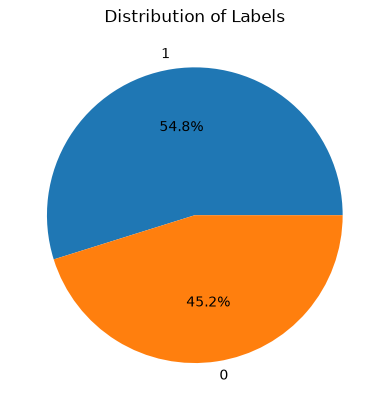

In [233]:
label_counts = df['label'].value_counts()
label_counts

plt.pie(label_counts, labels=label_counts.index, autopct='%1.1f%%')
plt.title('Distribution of Labels')
plt.show()

In [234]:
conflict = df.groupby("clean_text")["label"].nunique()
print((conflict > 1).sum())

0


In [235]:
df.isnull().sum()

title            0
text             0
subject          0
date             0
label            0
n_words          0
combined_text    0
clean_text       0
dtype: int64

In [236]:
df = df[df["clean_text"].str.split().str.len() >= 10]

In [237]:
data = df['clean_text']
label = df['label']

In [238]:
data.isnull().sum()

np.int64(0)

In [239]:
label.isnull().sum()

np.int64(0)

### Split the data into train , validation , test

In [240]:
X_train, X_temp, y_train, y_temp = train_test_split(
    data, label, test_size=0.2, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)

#### save the data as csv files in directory data / processed

In [241]:
train_df = pd.concat([X_train, y_train], axis=1)
val_df = pd.concat([X_val, y_val], axis=1)
test_df = pd.concat([X_test, y_test], axis=1)
print(train_df.isnull().sum())
print(val_df.isnull().sum())
print(test_df.isnull().sum())

clean_text    0
label         0
dtype: int64
clean_text    0
label         0
dtype: int64
clean_text    0
label         0
dtype: int64


In [ ]:
train_df.to_csv("../data/processed/ISOT/train.csv", index=False)
val_df.to_csv("../data/processed/ISOT/val.csv", index=False)
test_df.to_csv("../data/processed/ISOT/test.csv", index=False)